# Digital Image Processing Lab — Lab Task 03
## Image Enhancement and Intensity Transformations

**Name:** YOUR NAME HERE  
**Roll No:** 2024-SE-16  
**Session:** 2024-28 (SE) | **Semester:** Fifth  
**Lab Instructor:** Engr. Fahad Nisar  
**Department of Software Engineering, The University of Azad Jammu and Kashmir**

In [1]:
import os, json
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
DRY = {}          # dry-run results are collected here and saved at the end

def save_fig(name):
    plt.savefig(f"figures/{name}.png", dpi=110, bbox_inches="tight")

def show(ax, im, title):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)   # fixed 0-255 display range
    ax.set_title(title, fontsize=10)
    ax.axis("off")

def to_u8(x):
    # clip to 0-255 first, then convert; astype() truncates the fraction
    return np.clip(x, 0, 255).astype(np.uint8)

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.5.4


## 0. Load and validate the 8-bit grayscale image
The chosen image (`Butterfly.jpg`) is a colour image, so it is converted to grayscale once, saved as
`Butterfly_gray.png` and then re-loaded as a true single-channel 8-bit image. The original array is kept
unchanged (write-protected) and every operation works on a copy.

Colour image shape: (768, 1408, 3)
shape : (768, 1408)
dtype : uint8
min   : 0
max   : 255


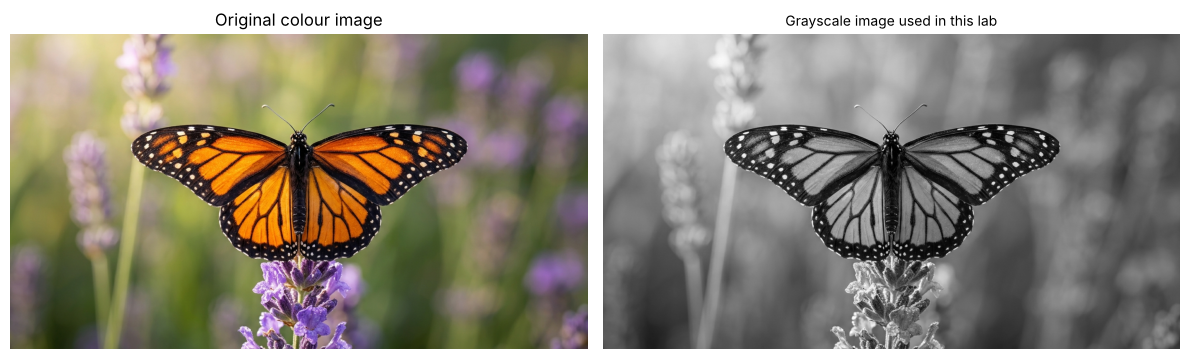

In [2]:
color = cv2.imread("Butterfly.jpg")
print("Colour image shape:", color.shape)

gray_conv = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)
cv2.imwrite("Butterfly_gray.png", gray_conv)

img = cv2.imread("Butterfly_gray.png", cv2.IMREAD_GRAYSCALE)
assert img is not None, "image failed to load"
assert img.ndim == 2 and img.dtype == np.uint8, "not an 8-bit grayscale image"
assert img.shape[0] >= 300 and img.shape[1] >= 300, "image smaller than 300x300"

original = img.copy()          # untouched reference copy
img.flags.writeable = False    # protects img from accidental in-place changes

print("shape :", img.shape)
print("dtype :", img.dtype)
print("min   :", img.min())
print("max   :", img.max())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(cv2.cvtColor(color, cv2.COLOR_BGR2RGB)); ax[0].set_title("Original colour image"); ax[0].axis("off")
show(ax[1], img, "Grayscale image used in this lab")
plt.tight_layout(); save_fig("00_load"); plt.show()

## 1. Brightness adjustment (β = +40 and −40)
`uint8` arithmetic wraps around (250 + 40 = 34), so the image is first converted to a wider type (`int16`),
the offset is added, the result is clipped to 0–255, and only then converted back to `uint8`.

Pixels that wrapped around with plain uint8 addition: 17554


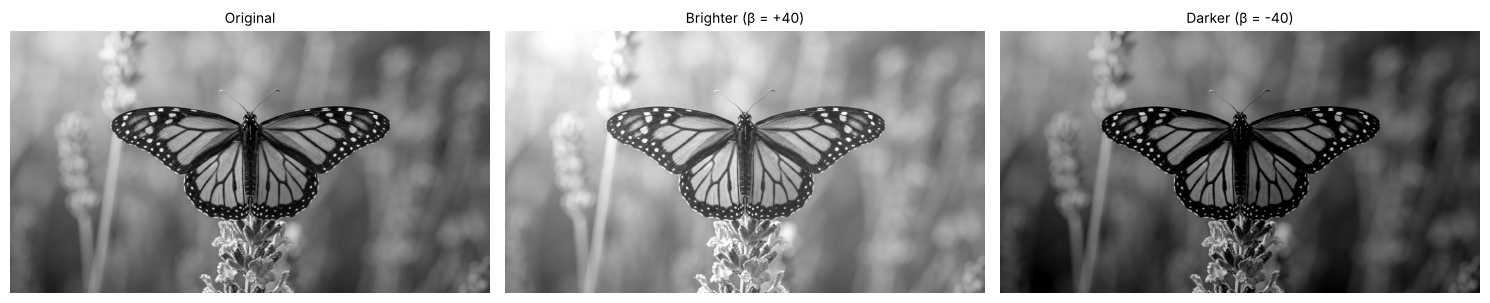

Mean  original / +40 / -40 : 118.16 157.96 79.31
Pixels = 255 in +40 image  : 18559
Pixels = 0   in -40 image  : 69180


In [3]:
bright = to_u8(img.astype(np.int16) + 40)
darker = to_u8(img.astype(np.int16) - 40)

# naive uint8 addition to demonstrate overflow (NOT used for results)
overflow_demo = img + np.uint8(40)
print("Pixels that wrapped around with plain uint8 addition:", int(np.sum(overflow_demo < img)))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
show(ax[0], img,    "Original")
show(ax[1], bright, "Brighter (β = +40)")
show(ax[2], darker, "Darker (β = -40)")
plt.tight_layout(); save_fig("01_brightness"); plt.show()

print("Mean  original / +40 / -40 :", round(img.mean(),2), round(bright.mean(),2), round(darker.mean(),2))
print("Pixels = 255 in +40 image  :", int(np.sum(bright == 255)))
print("Pixels = 0   in -40 image  :", int(np.sum(darker == 0)))

In [4]:
# +40 using nested loops (slow but explicit) and comparison with NumPy
h, w = img.shape
loop_bright = np.zeros_like(img)
for i in range(h):
    for j in range(w):
        v = int(img[i, j]) + 40
        if v > 255:
            v = 255
        loop_bright[i, j] = v

print("Nested-loop result identical to NumPy result:", np.array_equal(loop_bright, bright))

Nested-loop result identical to NumPy result: True


### Dry run 1 — Brightness, pixels [30, 80, 128, 180, 240]

In [5]:
px = np.array([30, 80, 128, 180, 240])
rows = []
for r in px:
    for b in (40, -40):
        raw = int(r) + b
        clipped = min(max(raw, 0), 255)
        rows.append([int(r), f"{b:+d}", raw, clipped, int(np.uint8(clipped))])
t1 = pd.DataFrame(rows, columns=["r", "β", "raw r+β", "clipped", "final uint8"])
display(t1)

# verification in Python
chk = to_u8(px.astype(np.int16) + 40), to_u8(px.astype(np.int16) - 40)
print("NumPy +40:", chk[0], " NumPy -40:", chk[1])
DRY["d1"] = t1.values.tolist()

,r,β,raw r+β,clipped,final uint8
0,30,+40,70,70,70
1,30,-40,-10,0,0
2,80,+40,120,120,120
3,80,-40,40,40,40
4,128,+40,168,168,168
5,128,-40,88,88,88
6,180,+40,220,220,220
7,180,-40,140,140,140
8,240,+40,280,255,255
9,240,-40,200,200,200


NumPy +40: [ 70 120 168 220 255]  NumPy -40: [  0  40  88 140 200]


**Lost detail:** with β = +40, the input 240 becomes 280 which is clipped to 255, so every input from 215 to 255
collapses onto 255 (highlights are lost). With β = −40, the input 30 becomes −10 which is clipped to 0, so every
input from 0 to 40 collapses onto 0 (shadows are lost). Clipped values cannot be recovered by applying the opposite shift.

## 2. Linear contrast from zero: s = αr + β, α = 1.5, β = 0

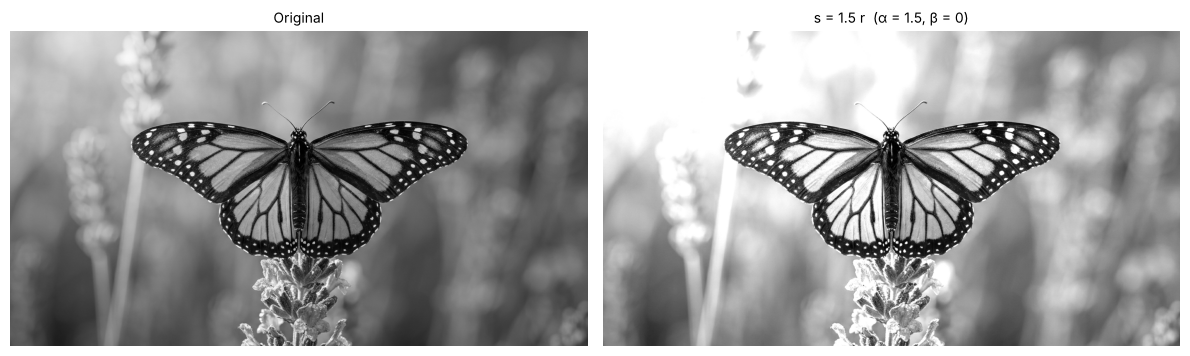

Mean original / 1.5r        : 118.16 172.0
Pixels = 255 original / 1.5r: 10 184219
Share saturated at 255 (1.5r): 17.04 %
All inputs >= 170 saturate  : True


In [6]:
lin15 = to_u8(img.astype(np.float32) * 1.5 + 0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
show(ax[0], img,   "Original")
show(ax[1], lin15, "s = 1.5 r  (α = 1.5, β = 0)")
plt.tight_layout(); save_fig("02_linear_contrast"); plt.show()

print("Mean original / 1.5r        :", round(img.mean(),2), round(lin15.mean(),2))
print("Pixels = 255 original / 1.5r:", int(np.sum(img==255)), int(np.sum(lin15==255)))
print("Share saturated at 255 (1.5r): %.2f %%" % (100*np.mean(lin15==255)))
print("All inputs >= 170 saturate  :", bool(np.all(lin15[img >= 170] == 255)))

### Dry run 2 — s = 1.5 r, pixels [30, 80, 128, 180, 240]

In [7]:
rows = []
for r in px:
    raw = 1.5 * r
    clipped = min(max(raw, 0), 255)
    final = int(clipped)                       # truncate
    rows.append([int(r), raw, clipped, final, "YES" if raw > 255 else "no"])
t2 = pd.DataFrame(rows, columns=["r", "1.5 r (raw)", "clipped", "truncated uint8", "saturated?"])
display(t2)
print("NumPy check:", to_u8(px.astype(np.float32) * 1.5))
DRY["d2"] = t2.values.tolist()

,r,1.5 r (raw),clipped,truncated uint8,saturated?
0,30,45.0,45.0,45,no
1,80,120.0,120.0,120,no
2,128,192.0,192.0,192,no
3,180,270.0,255.0,255,YES
4,240,360.0,255.0,255,YES


NumPy check: [ 45 120 192 255 255]


**Observation:** 180 → 270 and 240 → 360 are both clipped to 255, so these two pixels are saturated and become
indistinguishable. Multiplying by 1.5 brightens the whole image *and* stretches contrast, and the bright parts of the
butterfly's wings lose detail because anything above 170 turns white.

## 3. Contrast centred at 128: s = (r − 128)α + 128, α = 1.5 and 0.5

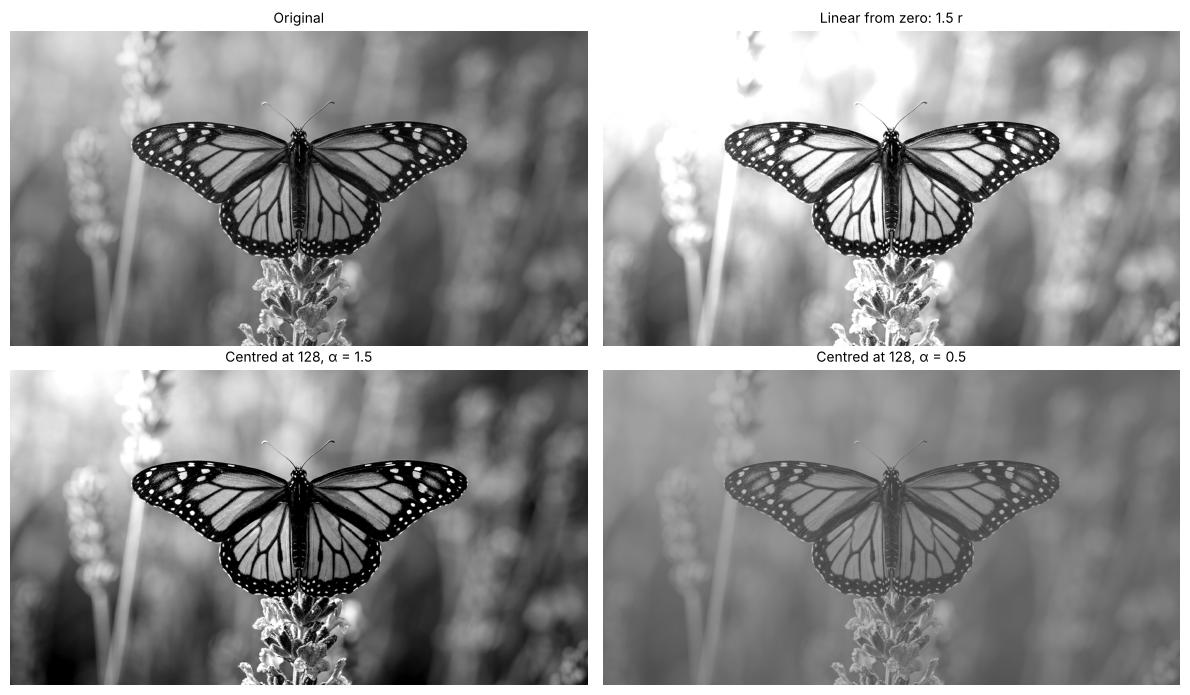

,mean,std,% at 0,% at 255
original,118.16,47.58,0.04,0.00
1.5 r,172.00,63.57,0.04,17.04
centred 1.5,114.63,66.72,6.89,1.94
centred 0.5,122.83,23.79,0.00,0.00


In [8]:
def centered(im, a):
    return to_u8((im.astype(np.float32) - 128) * a + 128)

c15 = centered(img, 1.5)
c05 = centered(img, 0.5)

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
show(ax[0,0], img,   "Original")
show(ax[0,1], lin15, "Linear from zero: 1.5 r")
show(ax[1,0], c15,   "Centred at 128, α = 1.5")
show(ax[1,1], c05,   "Centred at 128, α = 0.5")
plt.tight_layout(); save_fig("03_centered_contrast"); plt.show()

stats = pd.DataFrame({
    "mean":   [img.mean(), lin15.mean(), c15.mean(), c05.mean()],
    "std":    [img.std(),  lin15.std(),  c15.std(),  c05.std()],
    "% at 0": [100*np.mean(a==0)   for a in (img, lin15, c15, c05)],
    "% at 255":[100*np.mean(a==255) for a in (img, lin15, c15, c05)],
}, index=["original", "1.5 r", "centred 1.5", "centred 0.5"]).round(2)
display(stats)
DRY["stats3"] = stats.reset_index().values.tolist()

### Dry run 3 — s = (r − 128)α + 128, pixels [30, 80, 128, 180, 240]

In [9]:
rows = []
for r in px:
    d = int(r) - 128
    for a in (1.5, 0.5):
        raw = d * a + 128
        clipped = min(max(raw, 0), 255)
        rows.append([int(r), a, d, d*a, raw, clipped, int(clipped)])
t3 = pd.DataFrame(rows, columns=["r", "α", "r-128", "(r-128)α", "+128 (raw)", "clipped", "truncated"])
display(t3)
print("NumPy α=1.5:", centered(px, 1.5), " α=0.5:", centered(px, 0.5))
DRY["d3"] = t3.values.tolist()

,r,α,r-128,(r-128)α,+128 (raw),clipped,truncated
0,30,1.5,-98,-147.0,-19.0,0.0,0
1,30,0.5,-98,-49.0,79.0,79.0,79
2,80,1.5,-48,-72.0,56.0,56.0,56
3,80,0.5,-48,-24.0,104.0,104.0,104
4,128,1.5,0,0.0,128.0,128.0,128
5,128,0.5,0,0.0,128.0,128.0,128
6,180,1.5,52,78.0,206.0,206.0,206
7,180,0.5,52,26.0,154.0,154.0,154
8,240,1.5,112,168.0,296.0,255.0,255
9,240,0.5,112,56.0,184.0,184.0,184


NumPy α=1.5: [  0  56 128 206 255]  α=0.5: [ 79 104 128 154 184]


**At r = 128:** (128 − 128)·α + 128 = 128 for every α, so the centre value is a fixed point. Values above 128 move away
from (α > 1) or towards (α < 1) 128; this is a pure contrast change that does not change the mid-gray brightness,
unlike s = 1.5 r which also shifts brightness.

## 4. Image negative: s = 255 − r

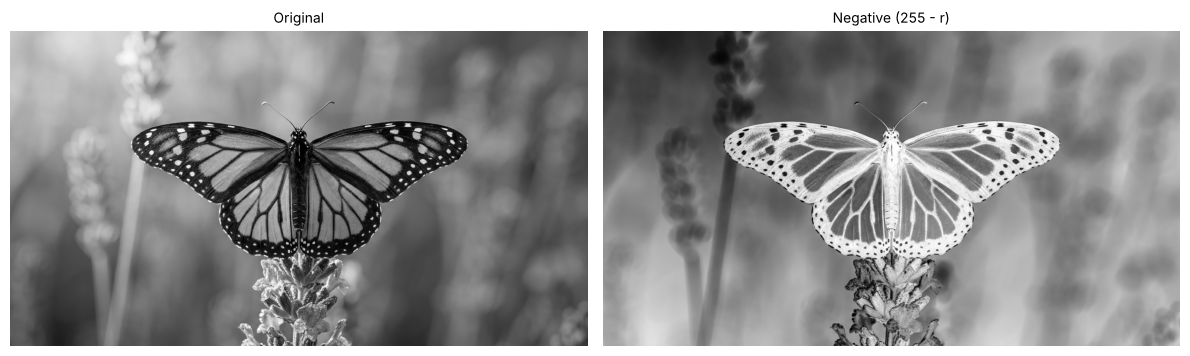

Negative of negative equals original: True


In [10]:
neg = 255 - img                      # uint8: 255 - r never goes below 0, so no overflow
neg2 = 255 - neg

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
show(ax[0], img, "Original")
show(ax[1], neg, "Negative (255 - r)")
plt.tight_layout(); save_fig("04_negative"); plt.show()

print("Negative of negative equals original:", np.array_equal(neg2, img))

**When it helps:** in medical images (X-rays, mammograms) bright-on-dark detail is often easier to inspect as
dark-on-white, and fine white structures embedded in large dark regions become easier to see when the image is inverted.

### Dry run 4 — negative, pixels [30, 80, 128, 180, 240]

In [11]:
rows = []
for r in px:
    n = 255 - int(r)
    rows.append([int(r), n, 255 - n, "yes" if 255 - n == r else "NO"])
t4 = pd.DataFrame(rows, columns=["r", "255 - r", "negative again", "equals original?"])
display(t4)
DRY["d4"] = t4.values.tolist()

,r,255 - r,negative again,equals original?
0,30,225,30,yes
1,80,175,80,yes
2,128,127,128,yes
3,180,75,180,yes
4,240,15,240,yes


## 5. Gamma correction: s = 255 (r/255)^γ, γ = 0.5 and 2.0
Convention used: the *output* is `255 * (r/255) ** γ` — γ < 1 brightens (lifts dark regions), γ > 1 darkens.

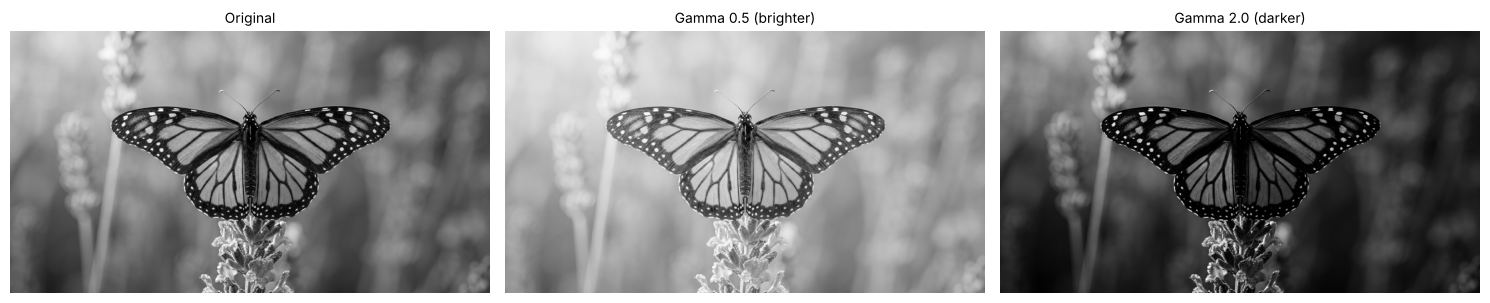

Mean of dark-region pixels  original: 35.04 | γ=0.5: 90.1 | γ=2.0: 5.6
γ=0.5: 0 -> 0   255 -> 255
γ=2.0: 0 -> 0   255 -> 255


In [12]:
def gamma_tf(im, g):
    return to_u8(255.0 * (im.astype(np.float64) / 255.0) ** g)

g05 = gamma_tf(img, 0.5)
g20 = gamma_tf(img, 2.0)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
show(ax[0], img, "Original")
show(ax[1], g05, "Gamma 0.5 (brighter)")
show(ax[2], g20, "Gamma 2.0 (darker)")
plt.tight_layout(); save_fig("05_gamma"); plt.show()

# effect on dark regions (pixels < 64 in the original)
dark_mask = img < 64
print("Mean of dark-region pixels  original:", round(img[dark_mask].mean(),2),
      "| γ=0.5:", round(g05[dark_mask].mean(),2), "| γ=2.0:", round(g20[dark_mask].mean(),2))

# 0 and 255 stay fixed
for g in (0.5, 2.0):
    print(f"γ={g}: 0 ->", gamma_tf(np.array([0]), g)[0], "  255 ->", gamma_tf(np.array([255]), g)[0])

### Dry run 5 — gamma, pixels [0, 64, 128, 192, 255]

In [13]:
gpx = np.array([0, 64, 128, 192, 255])
rows = []
for r in gpx:
    for g in (0.5, 2.0):
        norm = r / 255
        powr = norm ** g
        scaled = 255 * powr
        rows.append([int(r), g, round(norm, 6), round(powr, 6), round(scaled, 4), int(scaled)])
t5 = pd.DataFrame(rows, columns=["r", "γ", "r/255", "(r/255)^γ", "255·(...)", "truncated"])
display(t5)
print("NumPy γ=0.5:", gamma_tf(gpx, 0.5), " γ=2.0:", gamma_tf(gpx, 2.0))
DRY["d5"] = t5.values.tolist()

,r,γ,r/255,(r/255)^γ,255·(...),truncated
0,0,0.5,0.000000,0.000000,0.0000,0
1,0,2.0,0.000000,0.000000,0.0000,0
2,64,0.5,0.250980,0.500979,127.7498,127
3,64,2.0,0.250980,0.062991,16.0627,16
4,128,0.5,0.501961,0.708492,180.6654,180
5,128,2.0,0.501961,0.251965,64.2510,64
6,192,0.5,0.752941,0.867722,221.2691,221
7,192,2.0,0.752941,0.566920,144.5647,144
8,255,0.5,1.000000,1.000000,255.0000,255
9,255,2.0,1.000000,1.000000,255.0000,255


NumPy γ=0.5: [  0 127 180 221 255]  γ=2.0: [  0  16  64 144 255]


**Difference from the rounded slide example:** a slide may round the normalised value (e.g. 64/255 ≈ 0.25) before
applying the power, giving 255·√0.25 = 127.5 → 128. With full precision 64/255 = 0.250980…, √ = 0.500978…, and
255 × 0.500978 = 127.75, which truncates to **127**. Early rounding and rounding-up versus truncating explain the
difference of 1 grey level.

## 6. Grayscale histogram

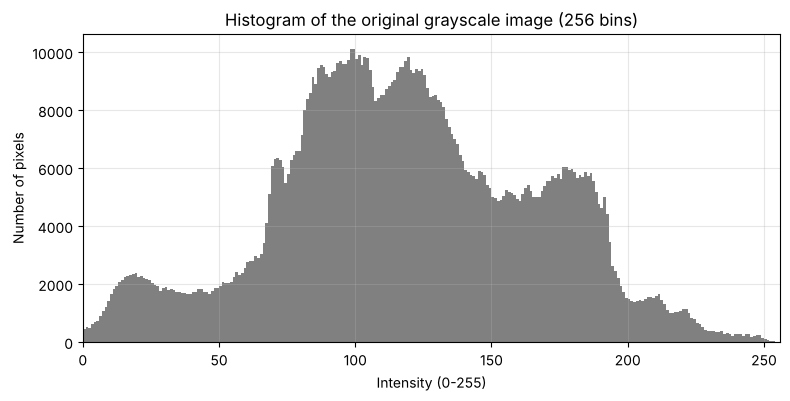

Most frequent intensity: 98 with 10122 pixels
Mean 118.16 | median 116.0 | std 47.58
Share < 64: 11.0 % | 64-191: 83.4 % | >= 192: 5.6 %


In [14]:
plt.figure(figsize=(9, 4))
plt.hist(img.ravel(), bins=256, range=(0, 256), color="gray")
plt.title("Histogram of the original grayscale image (256 bins)")
plt.xlabel("Intensity (0-255)"); plt.ylabel("Number of pixels")
plt.xlim(0, 256); plt.grid(alpha=0.3)
save_fig("06_histogram"); plt.show()

hist = np.bincount(img.ravel(), minlength=256)
print("Most frequent intensity:", hist.argmax(), "with", hist.max(), "pixels")
print("Mean %.2f | median %.1f | std %.2f" % (img.mean(), np.median(img), img.std()))
print("Share < 64: %.1f %% | 64-191: %.1f %% | >= 192: %.1f %%" %
      (100*np.mean(img<64), 100*np.mean((img>=64)&(img<192)), 100*np.mean(img>=192)))

**Interpretation:** the histogram is concentrated in the mid-tones (roughly 64–192, about 83 % of pixels) with its main
peak near 98, and only about 6 % of pixels are bright (≥ 192). The image therefore has moderate, somewhat low contrast
with a slightly dark-to-mid overall tone (mean ≈ 118), although some pure black (the wing borders) and a few
white spots exist at the extremes.

### Dry run 6 — A = [[0, 50, 50, 100], [100, 150, 200, 255]]

In [15]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]])
vals, counts = np.unique(A, return_counts=True)
total = A.size
t6 = pd.DataFrame({"intensity": vals, "frequency": counts, "probability": counts/total})
display(t6)
print("Total pixels:", total, "| sum of probabilities:", t6["probability"].sum())
DRY["d6"] = t6.values.tolist()
DRY["d6_total"] = int(total)

,intensity,frequency,probability
0,0,1,0.125
1,50,2,0.250
2,100,2,0.250
3,150,1,0.125
4,200,1,0.125
5,255,1,0.125


Total pixels: 8 | sum of probabilities: 1.0


**Why no pixel positions?** A histogram only counts how many pixels have each intensity. Different arrangements of the
same pixels (e.g. shuffled or rotated) give exactly the same histogram, so spatial information is lost.

## 7. Global histogram equalization (`cv2.equalizeHist`)

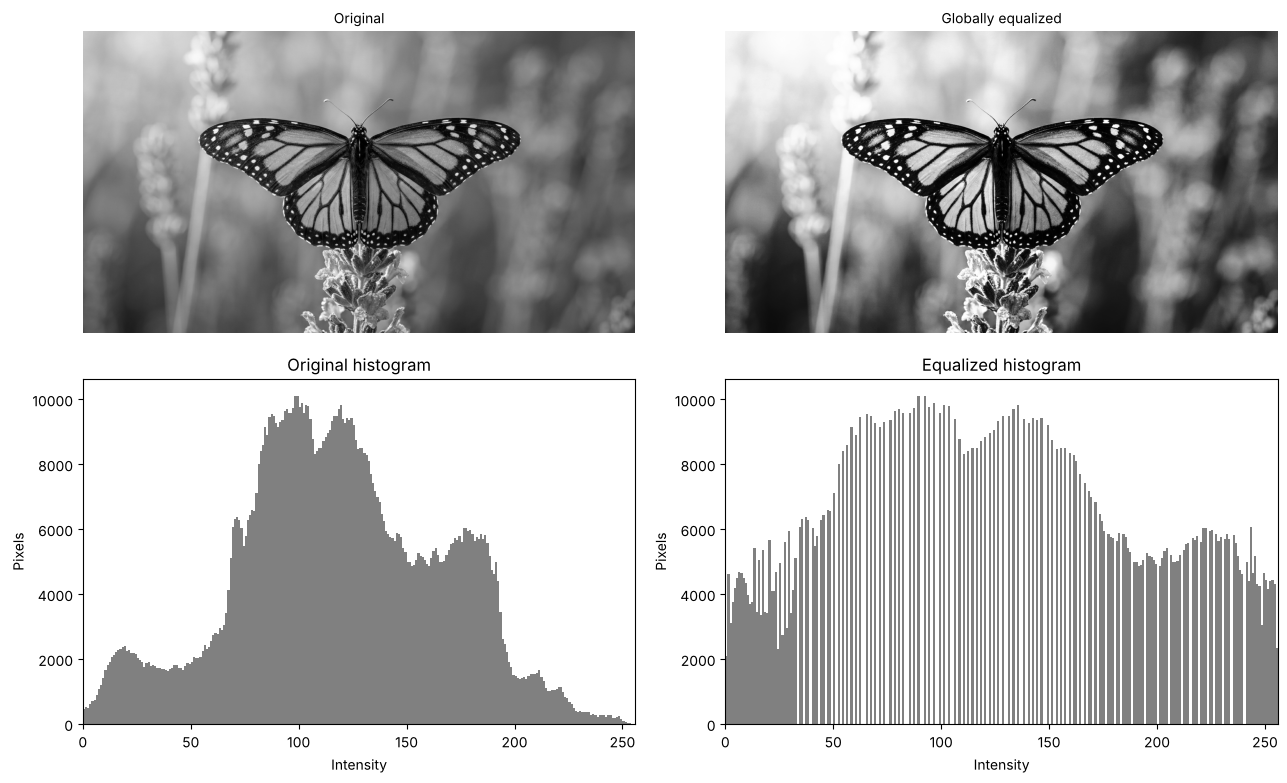

Std of intensities  original / equalized: 47.58 73.63
Laplacian std (detail+noise) original / equalized: 23.31 34.48


In [16]:
eq = cv2.equalizeHist(img)

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
show(ax[0,0], img, "Original")
show(ax[0,1], eq,  "Globally equalized")
ax[1,0].hist(img.ravel(), bins=256, range=(0,256), color="gray"); ax[1,0].set_title("Original histogram")
ax[1,1].hist(eq.ravel(),  bins=256, range=(0,256), color="gray"); ax[1,1].set_title("Equalized histogram")
for a in ax[1]: a.set_xlim(0,256); a.set_xlabel("Intensity"); a.set_ylabel("Pixels")
plt.tight_layout(); save_fig("07_equalization"); plt.show()

# simple noise / detail proxy: std of the Laplacian (high-frequency energy)
lap = lambda im: cv2.Laplacian(im, cv2.CV_64F).std()
print("Std of intensities  original / equalized:", round(img.std(),2), round(eq.std(),2))
print("Laplacian std (detail+noise) original / equalized:", round(lap(img),2), round(lap(eq),2))

**Discussion:** equalization stretches the narrow mid-tone range over 0–255, so the contrast and the visibility of wing
veins and background texture increase. The price is that noise and JPEG texture in the flat blurred background are
amplified too (the Laplacian/high-frequency energy rises), and the result can look harsh.

### Dry run 7 — pixels [50, 50, 100, 150]

In [17]:
p7 = np.array([50, 50, 100, 150])
vals, freq = np.unique(p7, return_counts=True)
cum = np.cumsum(freq)
cdf = cum / p7.size
cdfmin = cdf[cdf > 0].min()

def round_half_up(x):
    return int(np.floor(x + 0.5))

m1 = [round_half_up(255 * c) for c in cdf]
m2 = [round_half_up(255 * (c - cdfmin) / (1 - cdfmin)) for c in cdf]

t7 = pd.DataFrame({"intensity": vals, "freq": freq, "cumulative": cum, "CDF": cdf,
                   "255·CDF": 255*cdf, "map 1": m1,
                   "255(CDF-CDFmin)/(1-CDFmin)": 255*(cdf-cdfmin)/(1-cdfmin), "map 2": m2})
display(t7)

lut1 = dict(zip(vals, m1)); lut2 = dict(zip(vals, m2))
out1 = [lut1[v] for v in p7]; out2 = [lut2[v] for v in p7]
print("Output list, method 1 (255*CDF)         :", out1)
print("Output list, method 2 (CDF-min formula) :", out2)

cv_out = cv2.equalizeHist(p7.reshape(1, -1).astype(np.uint8)).ravel().tolist()
print("OpenCV equalizeHist                      :", cv_out)
print("Method 2 matches OpenCV:", out2 == cv_out)
DRY["d7"] = t7.values.tolist(); DRY["d7_out1"] = out1; DRY["d7_out2"] = out2; DRY["d7_cv"] = cv_out

,intensity,freq,cumulative,CDF,255·CDF,map 1,255(CDF-CDFmin)/(1-CDFmin),map 2
0,50,2,2,0.50,127.50,128,0.0,0
1,100,1,3,0.75,191.25,191,127.5,128
2,150,1,4,1.00,255.00,255,255.0,255


Output list, method 1 (255*CDF)         : [128, 128, 191, 255]
Output list, method 2 (CDF-min formula) : [0, 0, 128, 255]
OpenCV equalizeHist                      : [0, 0, 128, 255]
Method 2 matches OpenCV: True


**Observation:** method 1 never maps the darkest level to 0 (50 → 128), so the output does not use the full range;
method 2 subtracts CDFmin so the darkest level goes to 0 and the brightest to 255. OpenCV uses method 2.

## 8. CLAHE (`clipLimit = 2.0`, `tileGridSize = (8, 8)`)

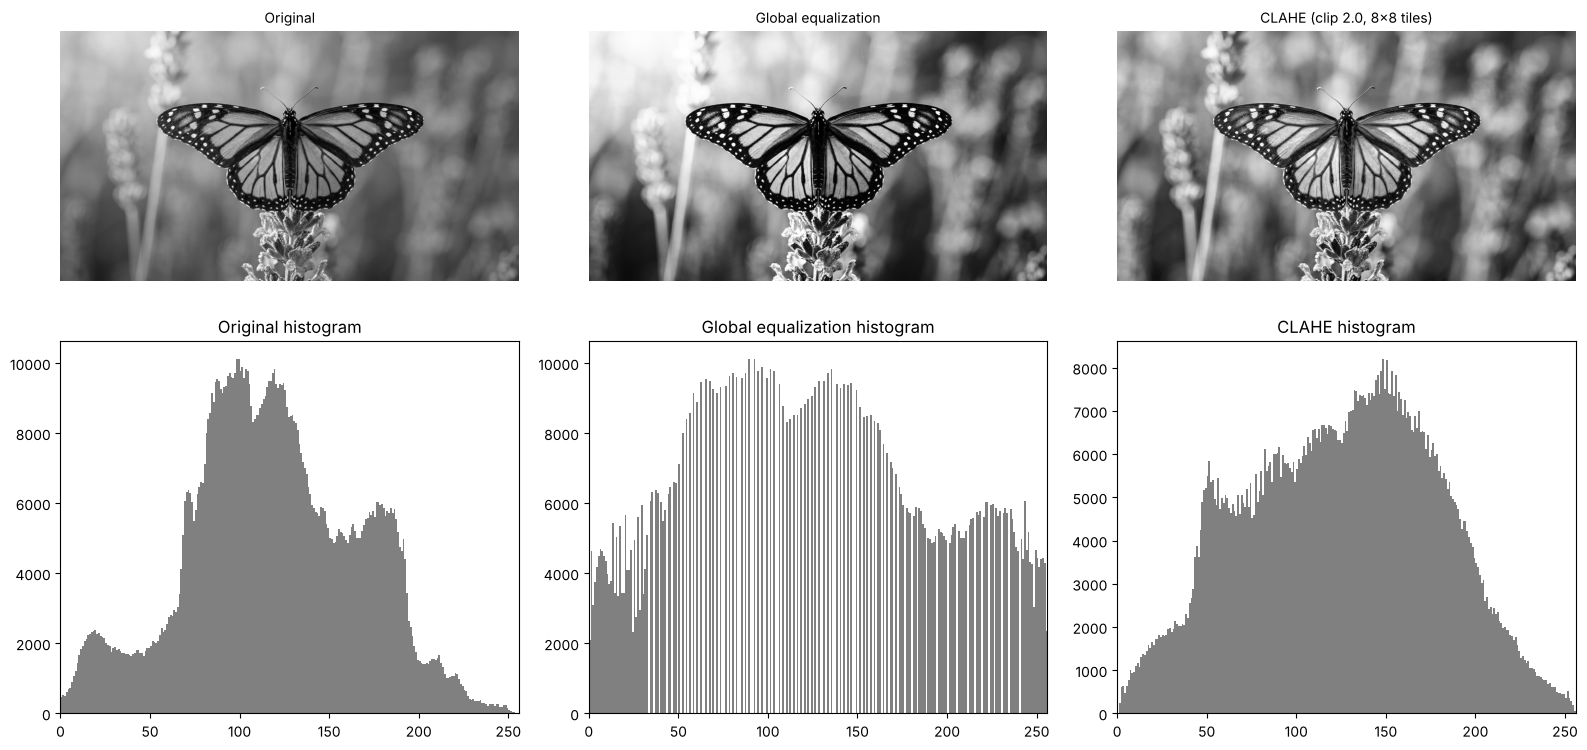

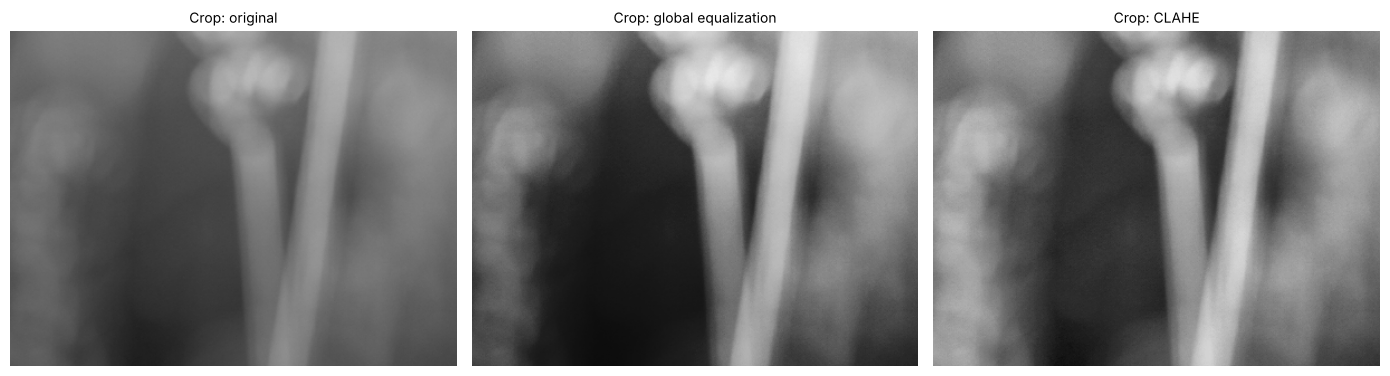

Std of intensities  orig / global / CLAHE: 47.58 73.63 53.09
Laplacian std       orig / global / CLAHE: 23.31 34.48 30.58


In [18]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
cl = clahe.apply(img)

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
show(ax[0,0], img, "Original")
show(ax[0,1], eq,  "Global equalization")
show(ax[0,2], cl,  "CLAHE (clip 2.0, 8x8 tiles)")
for k, (im, t) in enumerate([(img,"Original"), (eq,"Global equalization"), (cl,"CLAHE")]):
    ax[1,k].hist(im.ravel(), bins=256, range=(0,256), color="gray"); ax[1,k].set_title(t+" histogram")
    ax[1,k].set_xlim(0,256)
plt.tight_layout(); save_fig("08_clahe"); plt.show()

# zoom into a dark background crop and a wing crop for local-detail comparison
crop = (slice(450, 750), slice(0, 400))
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
show(ax[0], img[crop], "Crop: original")
show(ax[1], eq[crop],  "Crop: global equalization")
show(ax[2], cl[crop],  "Crop: CLAHE")
plt.tight_layout(); save_fig("08_clahe_crop"); plt.show()

print("Std of intensities  orig / global / CLAHE:", round(img.std(),2), round(eq.std(),2), round(cl.std(),2))
print("Laplacian std       orig / global / CLAHE:", round(lap(img),2), round(lap(eq),2), round(lap(cl),2))

**Discussion:** global equalization applies one mapping to the whole image, so regions of different lighting are
treated alike and large uniform areas can be over-stretched. CLAHE builds a separate mapping for each tile and limits
the contrast gain (clip limit), so local detail is enhanced under uneven lighting with less noise amplification.

**Note:** `tileGridSize = (8, 8)` means the image is divided into **8 × 8 = 64 tiles** (8 columns and 8 rows);
it is *not* a tile size of 8 × 8 pixels. For this image each tile is about 176 × 96 pixels.

### Dry run 8 — histogram [6, 2, 0, 0], absolute bin cap 4

In [19]:
h8 = np.array([6.0, 2.0, 0.0, 0.0])
cap = 4.0
clipped = np.minimum(h8, cap)
excess = (h8 - clipped).sum()
redist = clipped + excess / 4
cdf_old = np.cumsum(h8) / h8.sum()
cdf_new = np.cumsum(redist) / redist.sum()
t8 = pd.DataFrame({"bin": [0,1,2,3], "original": h8, "clipped (cap 4)": clipped,
                   "+excess/4": redist, "CDF old": cdf_old, "CDF new": cdf_new,
                   "255*CDF new": 255*cdf_new})
display(t8)
print("Excess removed:", excess, "-> each bin gets", excess/4)
print("Total after redistribution:", redist.sum())
DRY["d8"] = t8.values.tolist(); DRY["d8_excess"] = float(excess)

,bin,original,clipped (cap 4),+excess/4,CDF old,CDF new,255*CDF new
0,0,6.0,4.0,4.5,0.75,0.5625,143.4375
1,1,2.0,2.0,2.5,1.00,0.8750,223.1250
2,2,0.0,0.0,0.5,1.00,0.9375,239.0625
3,3,0.0,0.0,0.5,1.00,1.0000,255.0000


Excess removed: 2.0 -> each bin gets 0.5
Total after redistribution: 8.0


**Why interpolation?** Each tile has its own mapping, so two neighbouring tiles map the same intensity to different
output values. Without interpolation, visible block (tile) edges would appear. CLAHE therefore bilinearly interpolates
between the mappings of the four nearest tile centres for every pixel.  
*This simplified model differs from OpenCV's integer redistribution, and the absolute cap of 4 is not the same as
OpenCV's `clipLimit` parameter (which is a multiple of the average bin count).*

## 9. Fixed binary thresholding (T = 127)

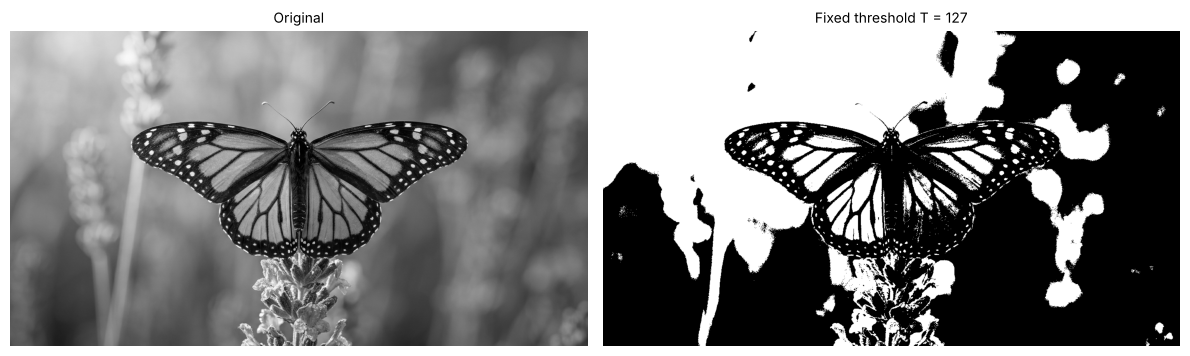

Unique values in the binary image: [  0 255]
White pixels: 433990 (40.13 %)


In [20]:
T = 127
_, bw127 = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
show(ax[0], img,   "Original")
show(ax[1], bw127, "Fixed threshold T = 127")
plt.tight_layout(); save_fig("09_fixed_threshold"); plt.show()

print("Unique values in the binary image:", np.unique(bw127))
print("White pixels: %d (%.2f %%)" % (np.sum(bw127==255), 100*np.mean(bw127==255)))

### Dry run 9 — pixels [0, 80, 127, 128, 180, 255]

In [21]:
p9 = np.array([0, 80, 127, 128, 180, 255])
rows = []
for r in p9:
    rows.append([int(r), 255 if r > 127 else 0, 255 if r > 180 else 0])
t9 = pd.DataFrame(rows, columns=["r", "T=127 (r>127)", "T=180 (r>180)"])
display(t9)
w127 = int((t9["T=127 (r>127)"] == 255).sum()); w180 = int((t9["T=180 (r>180)"] == 255).sum())
print("White pixels T=127:", w127, "| T=180:", w180)
cv_127 = cv2.threshold(p9.reshape(1,-1).astype(np.uint8), 127, 255, cv2.THRESH_BINARY)[1].ravel()
cv_180 = cv2.threshold(p9.reshape(1,-1).astype(np.uint8), 180, 255, cv2.THRESH_BINARY)[1].ravel()
print("OpenCV T=127:", cv_127, " T=180:", cv_180)
DRY["d9"] = t9.values.tolist(); DRY["d9_w"] = [w127, w180]

,r,T=127 (r>127),T=180 (r>180)
0,0,0,0
1,80,0,0
2,127,0,0
3,128,255,0
4,180,255,0
5,255,255,255


White pixels T=127: 3 | T=180: 1
OpenCV T=127: [  0   0   0 255 255 255]  T=180: [  0   0   0   0   0 255]


**Comparison:** raising T from 127 to 180 reduces the white pixels from 3 to 1, because the rule is strict
(`r > T`): 127 and 180 themselves are *not* white. A higher threshold keeps only the brightest pixels.

## 10. Otsu thresholding

Otsu threshold returned by OpenCV: 122.0


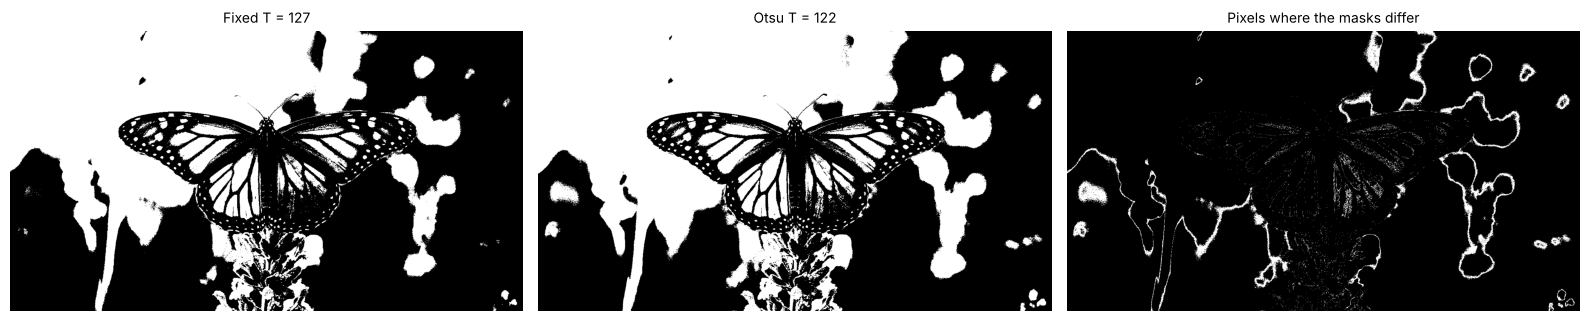

White pixels fixed / Otsu : 40.13 % / 44.32 %
Pixels that differ        : 45260 (4.19 %)


In [22]:
t_otsu, bw_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold returned by OpenCV:", t_otsu)

diff = bw127 != bw_otsu
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
show(ax[0], bw127,   "Fixed T = 127")
show(ax[1], bw_otsu, f"Otsu T = {t_otsu:.0f}")
show(ax[2], (diff*255).astype(np.uint8), "Pixels where the masks differ")
plt.tight_layout(); save_fig("10_otsu"); plt.show()

print("White pixels fixed / Otsu : %.2f %% / %.2f %%" % (100*np.mean(bw127==255), 100*np.mean(bw_otsu==255)))
print("Pixels that differ        : %d (%.2f %%)" % (diff.sum(), 100*diff.mean()))

### Dry run 10 — pixels [0, 1, 4, 5], T = 0 … 4

In [23]:
p10 = np.array([0, 1, 4, 5])
rows = []
for Tt in range(0, 5):
    c0 = p10[p10 <= Tt]; c1 = p10[p10 > Tt]
    w0 = len(c0)/len(p10); w1 = len(c1)/len(p10)
    m0 = c0.mean() if len(c0) else 0; m1_ = c1.mean() if len(c1) else 0
    rows.append([Tt, list(c0), list(c1), w0, w1, m0, m1_, w0*w1*(m0-m1_)**2])
t10 = pd.DataFrame(rows, columns=["T", "class 0 (r<=T)", "class 1 (r>T)", "w0", "w1", "μ0", "μ1", "w0·w1·(μ0-μ1)²"])
display(t10)
best = t10["w0·w1·(μ0-μ1)²"].max()
T_best = int(t10[np.isclose(t10["w0·w1·(μ0-μ1)²"], best)]["T"].min())   # smallest T among ties
print("Maximum between-class variance:", best, "-> chosen T =", T_best)
pred = np.where(p10 > T_best, 255, 0)
print("Predicted mask:", pred)
cv_T, cv_mask = cv2.threshold(p10.reshape(1,-1).astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("OpenCV Otsu threshold:", cv_T, " mask:", cv_mask.ravel(), " matches prediction:", np.array_equal(pred, cv_mask.ravel()))
DRY["d10"] = [[r[0], str(r[1]), str(r[2])] + [float(x) for x in r[3:]] for r in rows]
DRY["d10_T"] = T_best; DRY["d10_mask"] = pred.tolist(); DRY["d10_cv"] = [float(cv_T), cv_mask.ravel().tolist()]

,T,class 0 (r<=T),class 1 (r>T),w0,w1,μ0,μ1,w0·w1·(μ0-μ1)²
0,0,[0],"[1, 4, 5]",0.25,0.75,0.000000,3.333333,2.083333
1,1,"[0, 1]","[4, 5]",0.50,0.50,0.500000,4.500000,4.000000
2,2,"[0, 1]","[4, 5]",0.50,0.50,0.500000,4.500000,4.000000
3,3,"[0, 1]","[4, 5]",0.50,0.50,0.500000,4.500000,4.000000
4,4,"[0, 1, 4]",[5],0.75,0.25,1.666667,5.000000,2.083333


Maximum between-class variance: 4.0 -> chosen T = 1
Predicted mask: [  0   0 255 255]
OpenCV Otsu threshold: 1.0  mask: [  0   0 255 255]  matches prediction: True


## 11. Adaptive Gaussian thresholding (blockSize = 11, C = 2)

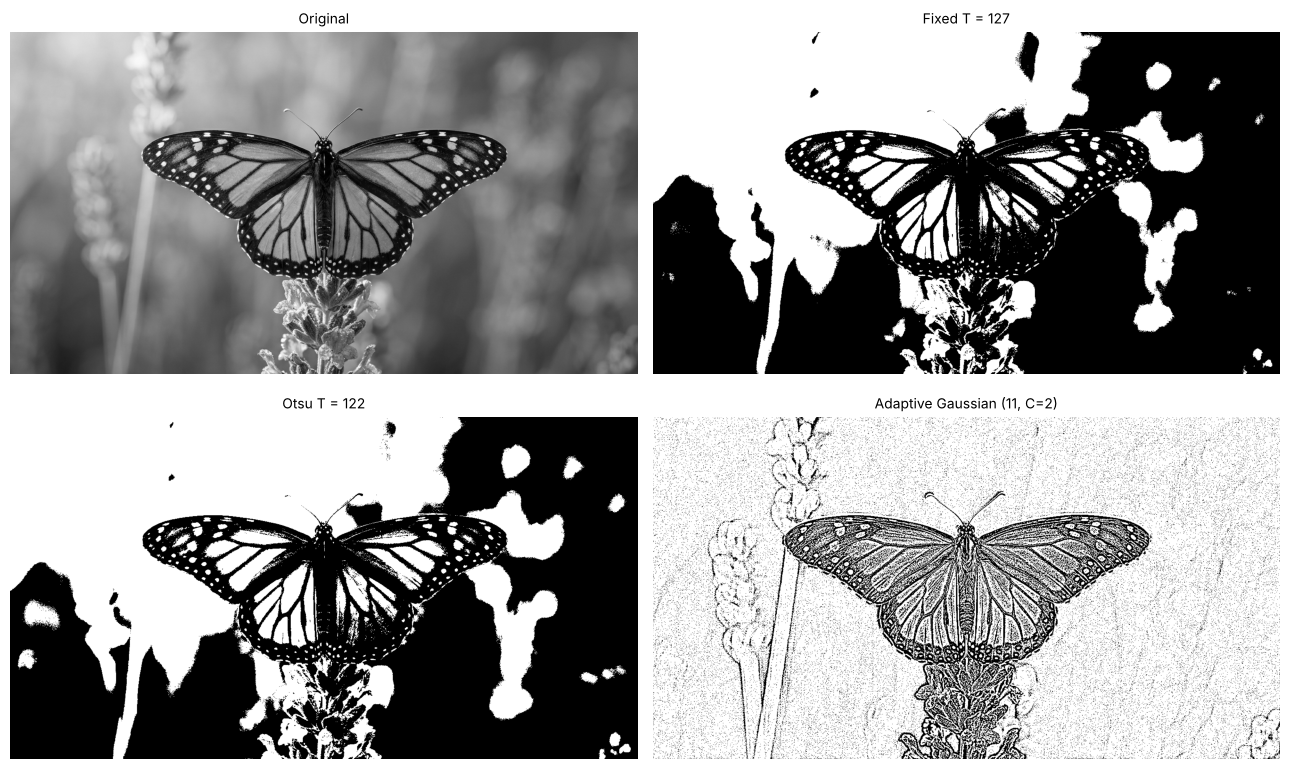

fixed     white pixels: 40.13 %
otsu      white pixels: 44.32 %
adaptive  white pixels: 84.42 %


In [24]:
adapt = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                              cv2.THRESH_BINARY, 11, 2)

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
show(ax[0,0], img,      "Original")
show(ax[0,1], bw127,    "Fixed T = 127")
show(ax[1,0], bw_otsu,  f"Otsu T = {t_otsu:.0f}")
show(ax[1,1], adapt,    "Adaptive Gaussian (11, C=2)")
plt.tight_layout(); save_fig("11_adaptive"); plt.show()

for name, m in [("fixed", bw127), ("otsu", bw_otsu), ("adaptive", adapt)]:
    print(f"{name:9s} white pixels: {100*np.mean(m==255):.2f} %")

**Discussion:** fixed and Otsu thresholds use one global value, so they split the image by absolute brightness (wing vs.
background). The adaptive Gaussian threshold compares each pixel with the weighted mean of its own 11 × 11 neighbourhood
minus C, so it highlights local edges and texture (wing veins, spots, outlines) and works well when lighting is uneven
(e.g. scanned documents with shadows), but it turns flat regions into noisy white/black speckle.

### Dry run 11 — 3 × 3 neighbourhood

In [25]:
N = np.array([[100, 100, 100], [100, 120, 140], [140, 140, 140]], dtype=float)
Wg = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
prod = N * Wg
mean_g = prod.sum()
Tt = mean_g - 2
print("Weighted products (N*W):\n", prod)
print("Weighted mean =", mean_g, "| T = mean - C =", Tt)
center = N[1, 1]
print("Centre pixel 120 > T ?", center > Tt, "->", 255 if center > Tt else 0)
print("Pixel equal to T (", Tt, ") > T ?", Tt > Tt, "->", 255 if Tt > Tt else 0)
DRY["d11"] = {"sum": float(prod.sum()), "mean": float(mean_g), "T": float(Tt),
              "center": int(center), "center_out": 255 if center > Tt else 0, "equal_out": 0}

Weighted products (N*W):
 [[ 6.25 12.5   6.25]
 [12.5  30.   17.5 ]
 [ 8.75 17.5   8.75]]
Weighted mean = 120.0 | T = mean - C = 118.0
Centre pixel 120 > T ? True -> 255
Pixel equal to T ( 118.0 ) > T ? False -> 0


**Result:** weighted mean = 1920/16 = 120, T = 120 − 2 = 118. The centre pixel 120 > 118, so it becomes **255**.
A pixel exactly equal to T (118) is **not** greater than T, so it becomes **0**.

## Summary of concepts
- **Clipping:** forcing out-of-range values to 0 or 255; it loses information permanently (saturation).
- **Overflow:** `uint8` arithmetic wraps around modulo 256 (250 + 40 = 34); avoided by using wider types and clipping before converting.
- **Brightness vs contrast:** brightness adds a constant (shifts all pixels); contrast multiplies (stretches differences). Centering at 128 changes contrast while keeping mid-gray fixed.
- **Gamma convention:** `s = 255 (r/255)^γ`; γ < 1 brightens dark regions, γ > 1 darkens; 0 and 255 never change.
- **Global vs local enhancement:** global (equalizeHist, fixed/Otsu) is simple and good for uniform lighting; local (CLAHE, adaptive) handles uneven lighting but may amplify noise.

In [26]:
with open("dryrun_results.json", "w") as f:
    json.dump(DRY, f, default=str)
print("Saved dry-run results and figures.")

Saved dry-run results and figures.
